# Содержание

1. [Функции](#s1)
   - [1.1 Функции для разметки](#s1_1)
   - [1.2 Функции для построения графиков](#s1_2)
   - [1.3 Функции для оценки корреляции](#s1_3)


2. [Загрузка данных и создание дополнительных параметров](#s2)
   - [2.1 Разметка данных на основе правил](#s2_1)
   - [2.2 Вывод](#s2_2)

3. [Кластеризация](#s3)
   - [3.1 Вывод](#s3_1)
     
4. [Проверка корреляции и автокорреляции](#s4)
   - [4.1 Вывод](#s4_1)

5. [Вывод](#s5)

<div style="border:solid purple 5px; padding: 20px"> 


<b>Цель проекта</b>

<hr>
Создать систему раннего оповещения о развитии аварийных режимов водно-химического режима котла, основанную на анализе многомерных временных рядов с дифференциацией типов уноса для выбора корректной корректирующей стратегии.

<hr>
    
В данной тетради проводится  <b> разметка данных для обучения многоклассовой модели. </b>

**df_listparam.csv** - преобразованная таблица обозначений кодов параметров 

**df_restor.csv** - данные после Data Preprocessing. 
       
<hr>

</div>  

#### Таблица 1 — Числовые критерии для классификации уноса солей

| Параметр | Обозначение | Единицы | Норма | Высокий | Критический | Аварийный |
|----------|-------------|---------|-------|---------|-------------|-----------|
| pH пара | $\text{pH}$ | ед. pH | $8.5 \div 9.5$ | $> 9.5$ |  | $< 7.5$ |
| Натрий в паре | $\text{Na}$ | мкг/кг | $< 25$ | $> 2.5σ$ | $> 25$ |
| Электропроводность пара | $\text{EC}$ | мкСм/см | $< 1.5$ | $> 2.5σ$ | $> 1.5$ |$> 3σ$ |

**Примечание:**  
- Пороги установлены для демонстрации режимов. 
Для котлов высокого давления предъявляются жесткие требования к химическому составу воды и пара.

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import warnings
warnings.filterwarnings('ignore')

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt 
import seaborn as sns

In [4]:
import modulekrug

In [5]:
from sklearn.model_selection import train_test_split

In [6]:
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

In [7]:
from sklearn.preprocessing import LabelEncoder

In [8]:
from scipy.stats import pearsonr
from scipy.stats import spearmanr

In [9]:
from datetime import datetime as dt

In [10]:
from statsmodels.tsa.seasonal import seasonal_decompose

In [11]:
from scipy import stats

In [12]:
# Снимаем ограничение на количество отображаемых столбцов
pd.set_option('display.max_columns', None)

## <a id="s1"></a> 1. Функции

### <a id="s1_1"></a> 1.1. Функции для разметки

In [13]:
def apply_deltas(data, columns, lags=[1, 2, 3]):
    
    df_copy = data.sort_index().copy()
    # Лаги и дельты
    for col in columns:
        if col not in df_copy.columns:
            print(f"Предупреждение: колонка {col} не найдена")
            continue
        for i in range(2,8,2):
            df_copy[f'{col}_mean_{i}h'] = df_copy[col].shift(1).rolling(i).mean()
            df_copy[f'{col}_std_{i}h'] = df_copy[col].shift(1).rolling(i).std()    
        
        for lag in lags:
            # Лаг
            df_copy[f'{col}_delta_{lag}'] = df_copy[col].diff(lag)
            # Дельта (изменение за lag часов). Оцениваем скорость изменения
        #оценим ускорение
        df_copy[f'{col}__accel'] = df_copy[col].diff().diff()  
        
    df_copy = df_copy.dropna()
    return df_copy

In [14]:
def apply_z_score(df, columns_for_z):
    df_copy = df.copy()
    for col in columns_for_z:
        if col not in df_copy.columns:
            #print(f"Предупреждение: колонка {col} не найдена")
            continue        
        mu = df_copy[col].mean()
        sigma = df_copy[col].std()           
        
        # Защита от деления на ноль
        if sigma == 0:
            df_copy[f'{col}_z'] = 0
        else:
            df_copy[f'{col}_z'] = (df_copy[col] - mu) / sigma  
    
    return df_copy    

In [15]:
def mark_na_complex(row, threshold_abs=25, threshold_sigma=2.5):
    """
    Комплексная разметка статуса Na    
    Аргументы:
    - row: строка DataFrame с колонками 'lba10cq204' (абсолютное) - Na в перегретом паре и 'lba10cq204_z' (нормированное)
    - threshold_abs: абсолютный порог (ПДК)
    - threshold_sigma: статистический порог (Z-score)
    """
    # Абсолютный контроль (физика)
    if row['lba10cq204'] > threshold_abs:
        return "критический"  # Превышение ПДК — авария
    
    # Статистическое раннее оповещение
    if row['lba10cq204_z'] > threshold_sigma:
        return "высокий"      # Отклонение от нормы — сигнал о возможной аварии
    
    return "норма"

In [16]:
def mark_ec_complex(row, threshold_abs=1.5, threshold_sigma=2.5):
    """
    Комплексная разметка статуса электропроводности
    Аргументы:
    - row: строка DataFrame с колонками 'lba10cq202' - электропроводность (абсолютное) и 'lba10cq202_z' (нормированное)
    - threshold_abs: абсолютный порог (ПДК)
    - threshold_sigma: статистический порог (Z-score)
    """
    # Абсолютный контроль (физика)
    if row['lba10cq202'] > threshold_abs:
        return "критический"  # Превышение ПДК — авария
    
    # Статистическое раннее оповещение
    if row['lba10cq202_z'] > threshold_sigma:
        return "высокий"      # Отклонение от нормы — сигнал о возможной аварии
    elif row['lba10cq202_z'] > 3:
        return "аварийный"      # Отклонение от нормы — сигнал о возможной аварии
    return "норма"

In [17]:
# Функция делает разметку типа "уноса солей" с паром. 
def classify_carryover(pH, Na, conductivity):
    if (pH > 8.5) and (pH < 9.5 ) and Na == "норма" and conductivity == "норма":
        return "Норма"
    elif Na != "норма":
        return "Натриевый унос (щелочной)"
    elif pH < 7.5 and Na == "норма" and (conductivity in ["критический", "высокий"]):
        return "Кислый унос (хлоридный)"
    elif pH < 7.5 or conductivity == "аварийный":
        return "Аварийный режим"
    else:
        return "Переходный режим"

### <a id="s1_2"></a> 1.2. Функции для построения графиков

In [18]:
def boxplots_for_month(data, parametrs):
    """
    Строит диаграммы размаха для указанных параметров по месяцам.
    
    """
    n_params = len(parametrs)
    
    fig, axes = plt.subplots(n_params, 1, figsize=(8, 3.5 * n_params))
    
    # Если только один график, преобразуем axes в список
    if n_params == 1:
        axes = [axes]
    
    for idx, param in enumerate(parametrs):
        name = modulekrug.get_name(param)['name'].iloc[0]
        sns.boxplot(data=data, x='month', y=param, ax=axes[idx])
        axes[idx].set_title(f'{param} - {name}', fontsize=10)
        axes[idx].set_ylabel(param)
        axes[idx].set_xlabel('Месяц', fontsize=8)
        axes[idx].tick_params(axis='x', labelsize=9, colors='#008080')
        axes[idx].tick_params(axis='y', labelsize=9, colors='#008080')
    
    fig.suptitle('Диаграмма размаха по месяцам', fontsize=14, y=1.02)
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show() 

In [19]:
def histplot_trends(data, paramets, n_sample=500):
    
    
    # Подсчет количества подграфиков
    n_plots = len(paramets)
    n_rows = (n_plots + 2) // 3  # округление вверх для строк
    n_cols = min(3, n_plots)
    # Создание фигуры с нужным размером
    fig_width = n_cols * 3.5  
    fig_height = n_rows * 3.0  
    
    fig = plt.figure(figsize=(fig_width, fig_height))
    
    for i, column in enumerate(list(paramets), 1):
        # Создание подграфика с динамическим позиционированием
        if i <= n_plots:
            plt.subplot(n_rows, n_cols, i)
            
            # Построение гистограммы с улучшенными параметрами
            sns.histplot(
                x=column, 
                data=data[paramets].sample(min(n_sample, len(data))), 
                stat='count', 
                kde=True, 
                color='#2E86AB',  # синий цвет
                edgecolor='white',  # Белая обводка для столбцов
                linewidth=0.5,
                alpha=0.8,  
                bins=30  
            )
            
            name = modulekrug.get_name(column)['name'].iloc[0]
            # Настройка внешнего вида графика
            plt.title(f'{column} - {name}', fontsize=12, fontweight='bold', color='#2F4F4F')
            plt.xlabel(column, fontsize=8)
            plt.ylabel('Count', fontsize=8)
            plt.grid(True, alpha=0.3, linestyle='--')              
            plt.xticks(rotation=45, ha='right')
    
    # Общая настройка макета
    plt.tight_layout(pad=3.0)  # Отступы между графиками
    plt.suptitle('Тенденции распределения параметров', 
                 fontsize=12,  y=1.02, color='#2F4F4F')

    return fig

In [20]:
def plot_classify(data):
    plt.figure(figsize=(5, 4), dpi= 80)
    data['тип_уноса'].value_counts().plot(kind='bar', color='skyblue', edgecolor='black')
    plt.title('Распределение типов уноса в датасете', fontsize=12,  color='#2F4F4F')
    plt.xlabel('Тип уноса', fontsize=8)
    plt.ylabel('Количество наблюдений', fontsize=8)
    plt.xticks(rotation=10, ha='right')
    plt.grid(axis='y', alpha=0.3)
    for i, v in enumerate(data['тип_уноса'].value_counts()):
        plt.text(i, v + 5, str(v), ha='center', va='bottom')
    plt.tight_layout()
    plt.show()

In [21]:
def view_df(selected_df, parametrs, print_trend=1, window='12h'):
    for name in selected_df:
        if name in sub_datasets_dict:
            df = sub_datasets_dict[name]
            print(f"\nАнализ данных: {name}. Размер выборки: {df.shape}\n".center(60))
            percent_table(df)

            if print_trend==1:
                modulekrug.plot_trends(df, parametrs, value_resample = window)
            
            histplot_trends(df, parametrs)
            print('Графики распределения')
            modulekrug.plot_corr(df, parametrs, 'spearman')
            plot_classify(df)

### <a id="s1_3"></a> 1.3. Функции для оценки корреляции

In [22]:
def salt_removal(data, parametrs,  method='spearman'):
    
    parametr1 = data[parametrs[0]]
    parametr2 = data[parametrs[1]]
    
    try:
        #получаем названия из модуля
        label_parametr1 = modulekrug.get_name(parametrs[0])['name'].iloc[0]
        label_parametr2 = modulekrug.get_name(parametrs[1])['name'].iloc[0]
    except:
        # Если modulekrug недоступен
        label_parametr1 = parametrs[0]
        label_parametr2 = parametrs[1]
    n = len(parametr1)
    if method.lower() == 'pearson':
        corr, p_value = stats.pearsonr(parametr1, parametr2)
        method_name = 'Пирсона'
    else:  
        corr, p_value = stats.spearmanr(parametr1, parametr2)
        method_name = 'Спирмена'

     # 4. Проверка значимости
    is_significant = p_value < 0.05
    
    
    plt.figure(figsize=(5, 4))
    plt.scatter(parametr1, parametr2, color='blue', s=100, zorder=3, alpha=0.6)

    # Линия тренда (если данных больше 2)
    if len(parametr1) > 2:
        z = np.polyfit(parametr1, parametr2, 1)
        p = np.poly1d(z)
    # Линия между 2.5-м и 97.5-м перцентилями (для устойчивости к выбросам)
        x_line = np.linspace(parametr1.quantile(0.025), parametr1.quantile(0.975), 100)
        y_line = p(x_line)
    
    plt.plot(x_line, y_line, "r--", alpha=0.7, label=f'Тренд (r_{method_name[:3]} = {corr:.2f})')
    
    # 7. Подписи и заголовок
    plt.xlabel(f'{label_parametr1}', fontsize=10)
    plt.ylabel(f'{label_parametr2}', fontsize=10)
    
    significance_text = 'ЗНАЧИМА' if is_significant else 'НЕ ЗНАЧИМА'
    title = (f'Точечный график: {parametrs[0]} & {parametrs[1]}\n'
             f'(n={n}, r_{method_name[:3]}={corr:.3f}, p={p_value:.4e} - {significance_text})')
    plt.title(title, fontsize=12)
    
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()

In [23]:
def percent_table(data):
    print("Распределение категорий (в %)".center(60))
    summary_table = pd.DataFrame({
                'Уровень в барабане': (data['level'].value_counts() / len(data) * 100).round(1),
                'pH перегр.пар': (data['ph'].value_counts() / len(data) * 100).round(1),
                'Электропр.пар': (data['ec_status'].value_counts() / len(data) * 100).round(1),
                'Na перегр.пар': (data['na_status'].value_counts() / len(data) * 100).round(1)}).fillna(0)
    print(summary_table.T)

In [24]:
# Смотрим корреляцию в зависимости от уровня в барабане
def salt_corr(data, parametrs, print_table_corr = False):
    for i in  data['level'].unique():
        if data[data['level']==i].shape[0]>2:
           print(f'\nУровень в барабане {i}\n')
           display(data[data['level']==i][parametrs].describe())
           modulekrug.plot_corr(data[data['level']==i], parametrs, 'spearman', print_table_corr)

## <a id="s2"></a> 2. Загрузка данных и создание дополнительных параметров

In [25]:
#загрузка словаря параметров
df_head = pd.read_csv('df_listparam.csv')

In [26]:
df_restor = pd.read_csv('df_restor.csv', index_col ='data_time', parse_dates=[0])

In [27]:
df_restor.head()

,hal40cf001,lba10cq204,lba10cq202,lba10cq201,had10cl001,hah90ct001,hha10cp001,had10cp001,lba10cf001,lba08cp001,month,work
data_time,,,,,,,,,,,,
2017-01-01 01:00:00,0.557734,18.889343,1.017061,9.187409,-10.367019,524.024597,-4.114055,104.986763,173.297531,97.683365,1.0,1
2017-01-01 02:00:00,0.588433,17.704405,1.030290,9.174880,-8.797795,522.886475,-4.023304,104.860405,173.493317,97.542007,1.0,1
2017-01-01 03:00:00,0.624670,17.130402,0.964971,9.217010,-10.776489,517.675110,-4.313242,104.710243,173.216736,97.399071,1.0,1
2017-01-01 04:00:00,0.558772,18.007931,1.044697,9.179220,-9.367927,523.403137,-4.315660,104.688377,173.602402,97.359032,1.0,1
2017-01-01 05:00:00,0.574724,19.552386,1.015224,9.242821,-9.449389,523.734619,-4.371890,104.454094,174.052734,97.112206,1.0,1


In [28]:
print('Список параметров')
modulekrug.find_values_by_index(df_restor.columns)

Список параметров


['hal40cf001 - Fконд на 1впр.н.А',
 'lba10cq204 - Na       перегр.п',
 'lba10cq202 - Эл.пров. перегр.п',
 'lba10cq201 - рН пер.п от котла',
 'had10cl001 - L в бар  котла т1',
 'hah90ct001 - Тост.пар в ПСК т1',
 'hha10cp001 - Ртопка 1 вверху',
 'had10cp001 - Р бараб. котла',
 'lba10cf001 - Fост.пар за котл.',
 'lba08cp001 - Рпара в  8сек.ГПП',
 'month - month',
 'work - work']

In [29]:
print(f'Временной диапазон данных {[df_restor.index[0]]} - {[df_restor.index[-1]]}\n')

Временной диапазон данных [Timestamp('2017-01-01 01:00:00')] - [Timestamp('2017-12-31 23:00:00')]



In [30]:
df_restor['hour'] = df_restor.index.hour
df_restor['day_of_week'] = df_restor.index.dayofweek

df_restor['hour_sin'] = np.sin(2 * np.pi * df_restor['hour'] / 24)
df_restor['hour_cos'] = np.cos(2 * np.pi * df_restor['hour'] / 24)
df_restor['dow_sin'] = np.sin(2 * np.pi * df_restor['day_of_week'] / 7)
df_restor['dow_cos'] = np.cos(2 * np.pi * df_restor['day_of_week'] / 7)

df_restor = df_restor.drop(['hour', 'day_of_week'], axis=1)

In [31]:
def group_level(value, norma = 0):
    if value <= norma - 10:
        return "низкий"
    elif value >= norma + 10:
        return "высокий" 
    else:
        return "норма"
#метки уровня в барабане
df_restor['level'] = df_restor['had10cl001'].apply(group_level)        

In [32]:
def group_pH(value):
    if value < 8.5:
        return "низкий"
    elif value > 9.5:
        return "высокий" 
    else:
        return "норма"
#метки pH перегретого пара
df_restor['ph'] = df_restor['lba10cq201'].apply(group_pH)        

In [33]:
# Список приборов учета химконтроля в барабане котла
list_cq = df_head[df_head['position'].str.contains("cq", case=False)].set_index('position')
print(f'\nТаблица параметров\n')
display(list_cq)


Таблица параметров



,units,min,max,name
position,,,,
lba10cq204,мкг/л,0,100.0,Na перегр.п
lba10cq202,мкСм/см,0,5.0,Эл.пров. перегр.п
lba10cq201,рН,0,15.3,рН пер.п от котла


In [34]:
# Список приборов учета Na (натрий) и электропроводности
list_ec = df_head[df_head['name'].str.contains("Na|Эл", case=False)].set_index('position')
display(list_ec)

,units,min,max,name
position,,,,
lba10cq204,мкг/л,0,100.0,Na перегр.п
lba10cq202,мкСм/см,0,5.0,Эл.пров. перегр.п


### <a id="s2_2"></a> 2.2.Разметка данных на основе правил

При создании датасетов сделаем 
- добавим разности временного ряда,  скользящее среднее, скользящее стандартное отклонение и ускорение.
- z - преобразование у параметров Na (натрий) и электропроводности.

- сделаем разметку данных на основе правил (rule-based разметка) установленными экспертно с помощью функций:

  mark_na_complex (Определяем статус Na)

  mark_ec_complex (Определяем статус электропроводности)

  classify_carryover (Делаем разметку тип уноса)


In [35]:
list_cq = df_head[df_head['position'].str.contains("cq", case=False)]['position']
columns_for_z = list_ec.index.to_list()

df_restor['group_id'] = (df_restor['work'].diff() != 0).cumsum()

# Фильтруем только work==1 и группируем
sub_datasets_dict = {}

for group, data in df_restor[df_restor['work'] == 1].groupby('group_id'):
    if len(data) >= 48:  # не менее 48 часов непрерывной работы 
        # Сортируем по времени
        data = data.sort_index()
        # Создаем колонку с часами от начала пуска котла
        data['hours_from_start'] = (data.index - data.index[0]).total_seconds() / 3600.0
        
        # находим разницы, mean, std и лаги
        data = apply_deltas(data, list_cq)
        # делаем z-преобразование
        data = apply_z_score(data, columns_for_z)
        
        data['na_status'] = data.apply(mark_na_complex, axis=1)
        data['ec_status'] = data.apply(mark_ec_complex, axis=1)
        data['тип_уноса'] = data.apply(
                lambda row: classify_carryover(row['lba10cq201'], row['na_status'], row['ec_status']), 
                     axis=1)
        # Сохраняем в словарь
        dataset_name = f"dataset_{group}"
        sub_datasets_dict[dataset_name] = data
        print(f"{dataset_name}: {data.index[0]} - {data.index[-1]}, длительность: {data['hours_from_start'].iloc[-1]:.1f} ч")

dataset_1: 2017-01-01 07:00:00 - 2017-04-06 01:00:00, длительность: 2280.0 ч
dataset_3: 2017-04-06 13:00:00 - 2017-05-02 16:00:00, длительность: 633.0 ч
dataset_5: 2017-05-04 17:00:00 - 2017-05-08 05:00:00, длительность: 90.0 ч
dataset_7: 2017-05-18 11:00:00 - 2017-06-03 03:00:00, длительность: 382.0 ч
dataset_9: 2017-06-09 05:00:00 - 2017-07-12 00:00:00, длительность: 793.0 ч
dataset_11: 2017-08-15 16:00:00 - 2017-08-31 18:00:00, длительность: 392.0 ч
dataset_13: 2017-09-01 05:00:00 - 2017-11-01 21:00:00, длительность: 1486.0 ч
dataset_15: 2017-11-11 01:00:00 - 2017-11-12 18:00:00, длительность: 47.0 ч
dataset_17: 2017-11-13 18:00:00 - 2017-11-21 11:00:00, длительность: 191.0 ч


У нас получилось 9 периодов, когда котел непрерывно работал более 48 часов подряд. 

Посмотрим на примере нескольких датасетов распределение типов уноса, тренды, корреляцию. 

   
Анализ данных: dataset_1. Размер выборки: (2275, 55)
   
               Распределение категорий (в %)                
                    высокий  критический  низкий  норма
Уровень в барабане      0.0          0.0     7.9   92.1
pH перегр.пар           3.3          0.0    37.2   59.5
Электропр.пар           0.0         39.8     0.0   60.2
Na перегр.пар           0.0          6.3     0.0   93.7
Графики распределения


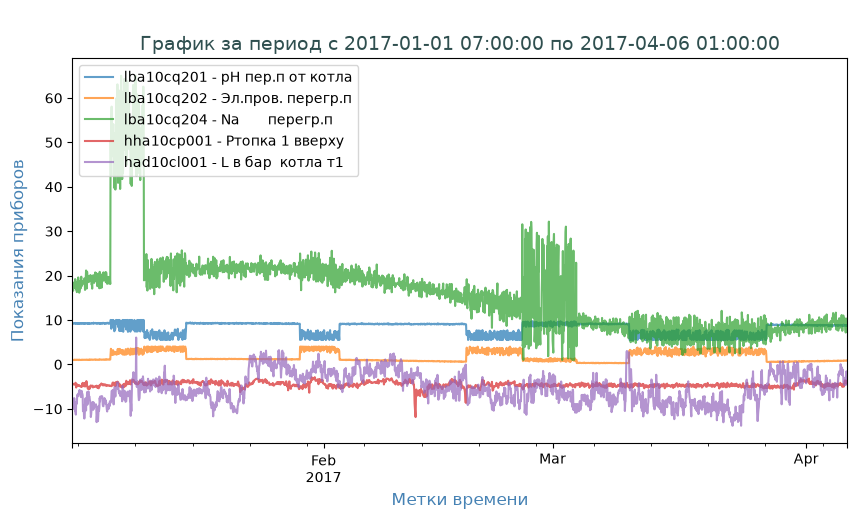

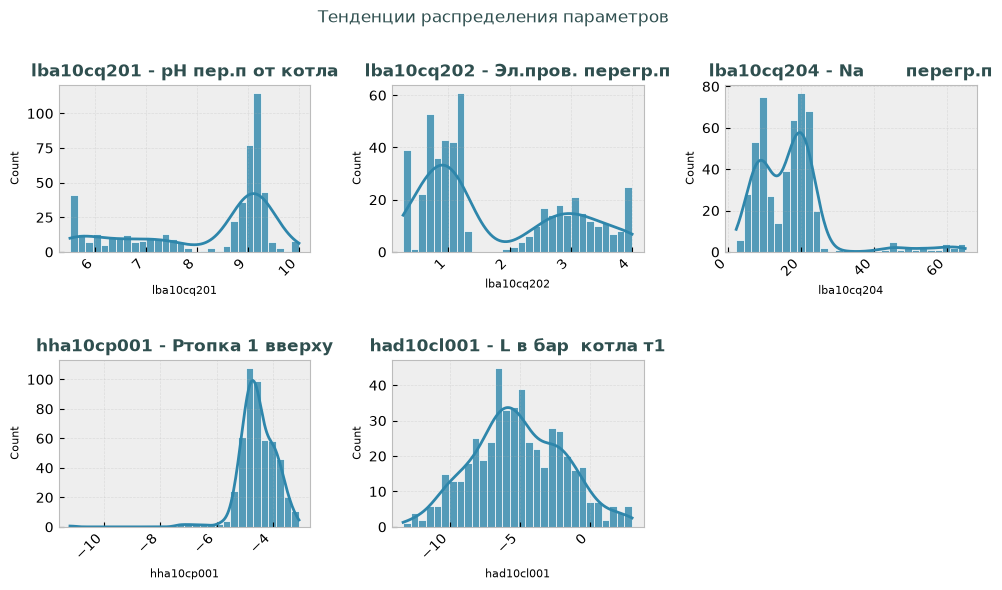

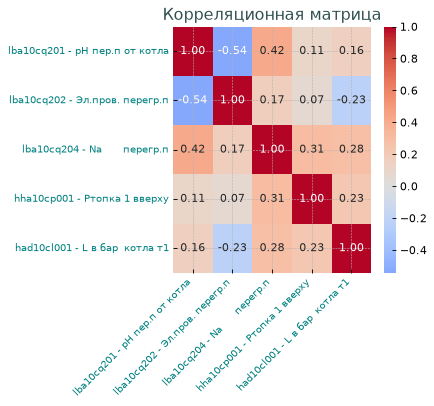

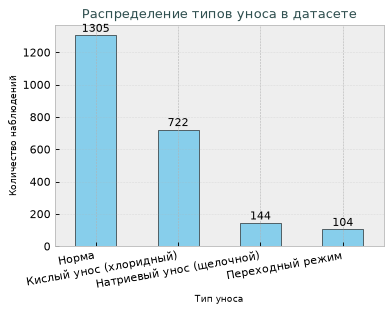

   
Анализ данных: dataset_3. Размер выборки: (628, 55)
    
               Распределение категорий (в %)                
                    критический  низкий  норма
Уровень в барабане          0.0    13.5   86.5
pH перегр.пар               0.0    47.9   52.1
Электропр.пар              70.9     0.0   29.1
Na перегр.пар              21.7     0.0   78.3
Графики распределения


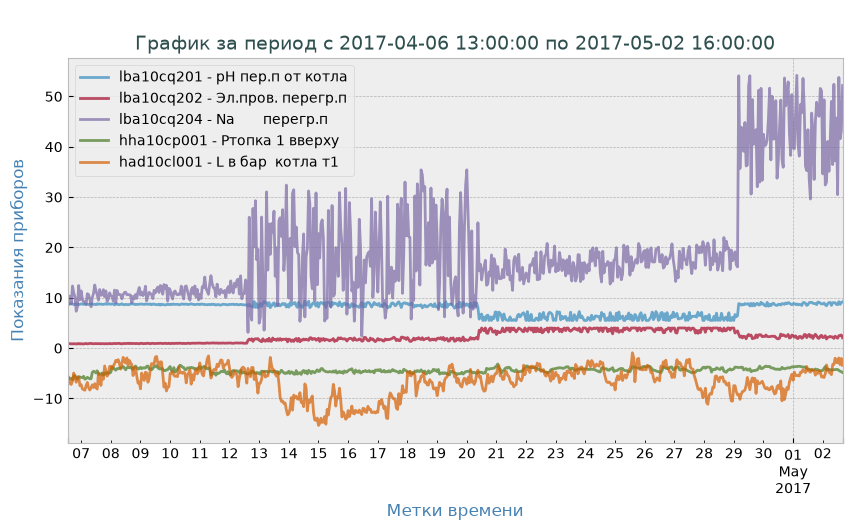

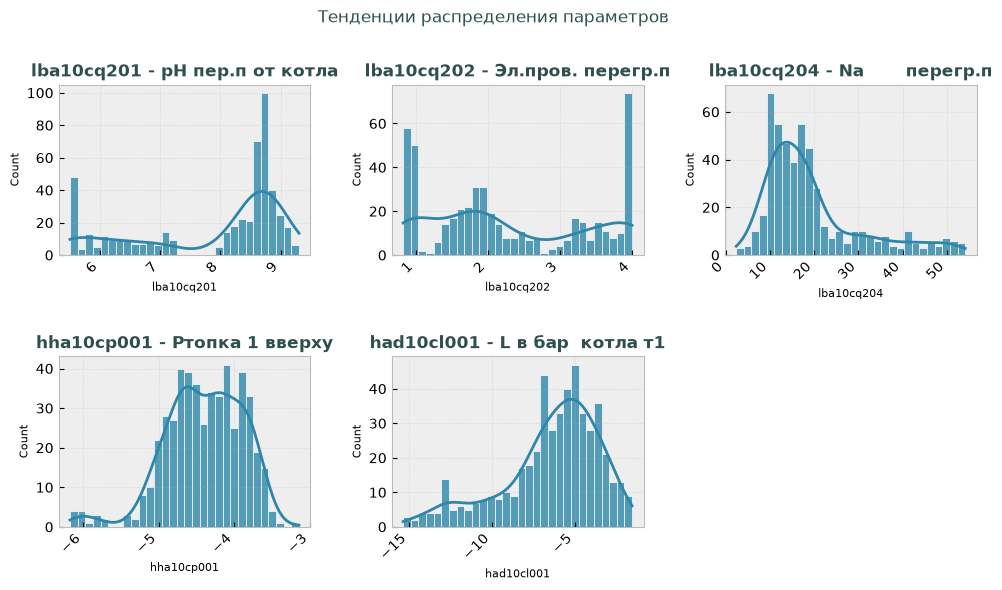

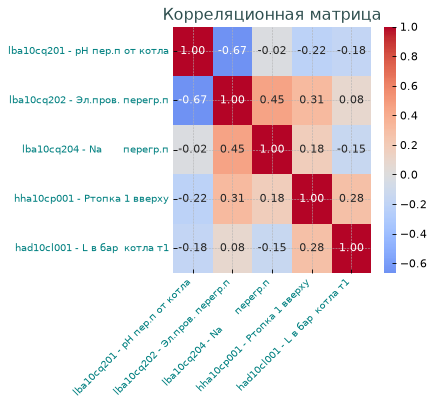

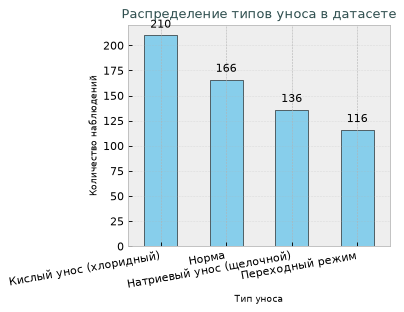

   
Анализ данных: dataset_9. Размер выборки: (788, 55)
    
               Распределение категорий (в %)                
                    высокий  критический  низкий  норма
Уровень в барабане      0.3          0.0     0.0   99.7
pH перегр.пар          23.2          0.0    18.7   58.1
Электропр.пар           0.0         35.0     0.0   65.0
Na перегр.пар           0.0         29.6     0.0   70.4
Графики распределения


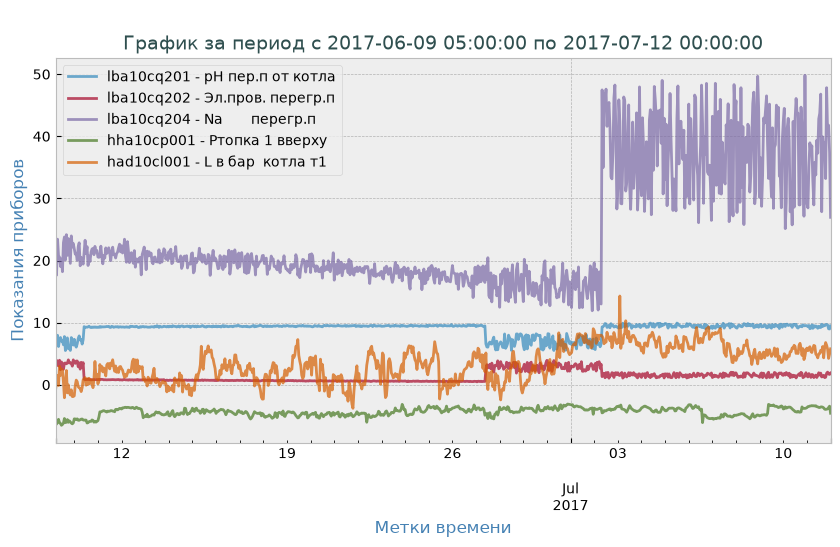

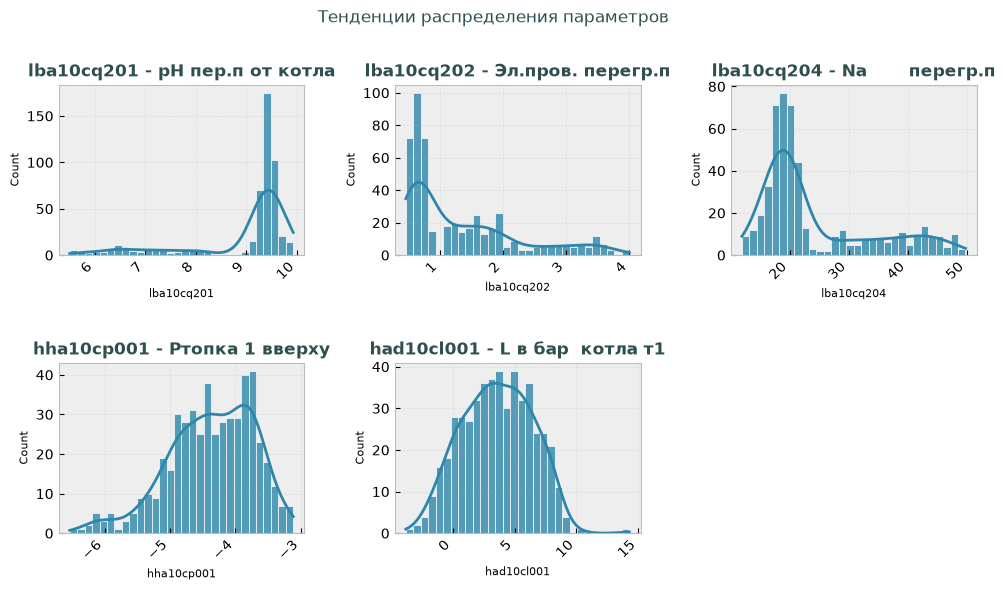

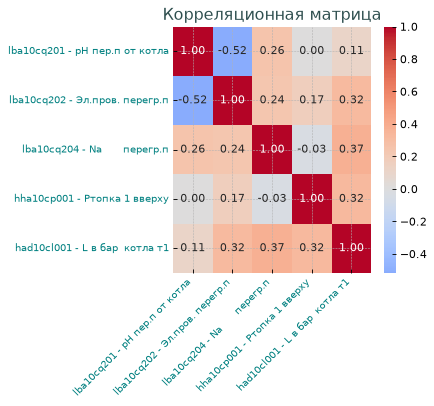

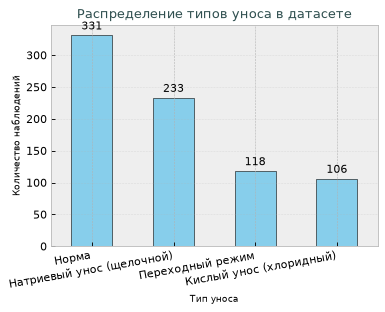

  
Анализ данных: dataset_13. Размер выборки: (1481, 55)
   
               Распределение категорий (в %)                
                    высокий  критический  низкий  норма
Уровень в барабане      0.5          0.0     0.9   98.6
pH перегр.пар           0.0          0.0    42.7   57.3
Электропр.пар           0.0         84.8     0.0   15.2
Na перегр.пар           0.0         48.1     0.0   51.9
Графики распределения


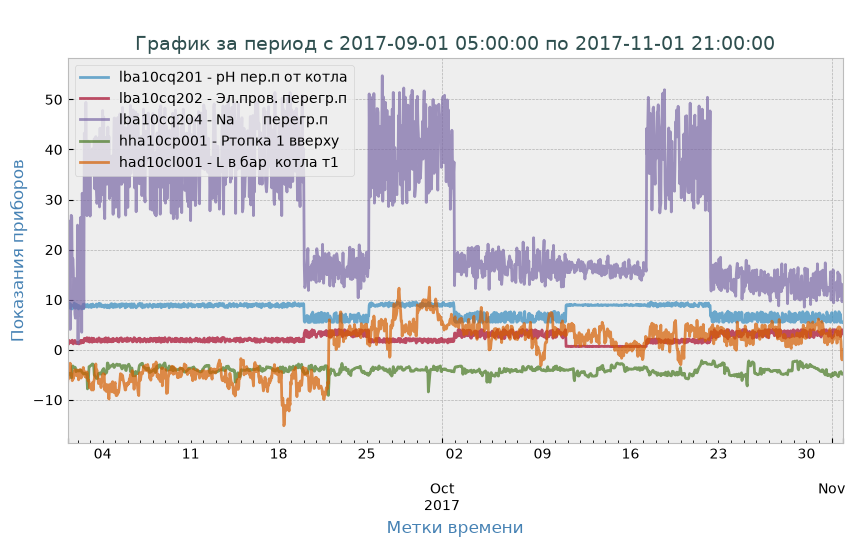

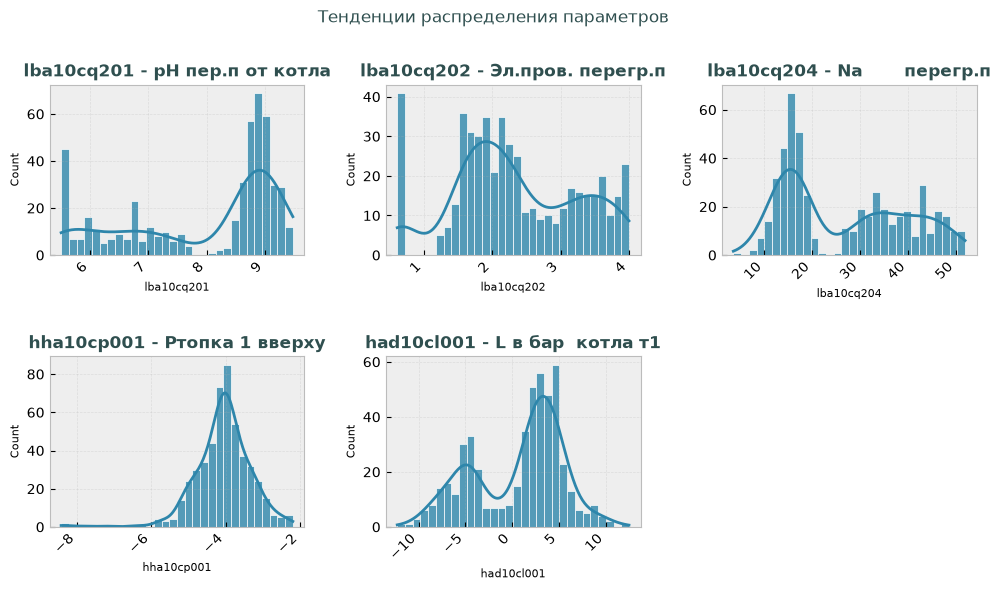

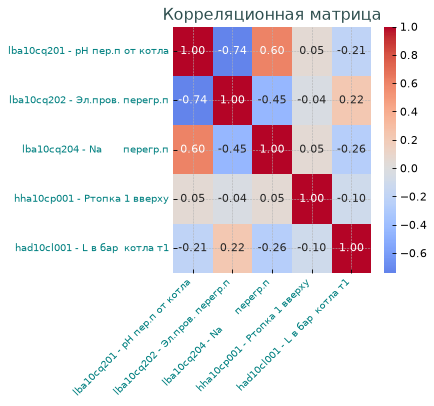

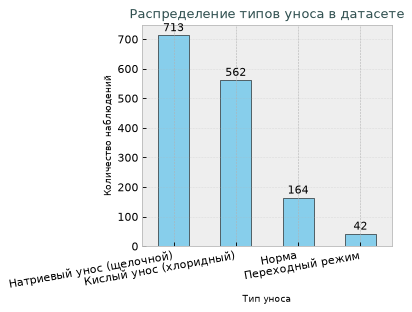

In [36]:
parametrs = ['lba10cq201', 'lba10cq202', 'lba10cq204', 'hha10cp001', 'had10cl001']
list_df = ['dataset_1', 'dataset_3', 'dataset_9', 'dataset_13']
view_df(list_df, parametrs, print_trend=1, window='1h')

Объединим полученные датасеты в один.

In [37]:
datasets_to_merge = sub_datasets_dict.keys()
df_merged = pd.concat([sub_datasets_dict[name] for name in datasets_to_merge])
print(f"Общий размер: {len(df_merged)}")
print("\nРаспределение классов в объединенном датасете:")
print(df_merged['тип_уноса'].value_counts())

Общий размер: 6249

Распределение классов в объединенном датасете:
тип_уноса
Кислый унос (хлоридный)      2121
Норма                        2091
Натриевый унос (щелочной)    1491
Переходный режим              546
Name: count, dtype: int64


### <a id="s2_3"></a> 2.2. Вывод

Полученные датасеты с rule-based разметкой указывают на системную проблему с солесодержанием в паре. В каждом из периодов встречается какой-нибудь тип уноса. Коэффициент корреляции между pH пара и электропроводностью пара доходит до **r=-0,76** . Это довольно сильная обратная связь. В нашем случае действует правило **«Много солей (высокая проводимость) → вода становится кислой (низкий pH)»**.

Сделаем оценку с помощью алгоритма k-means, который объединит похожие объекты, и сравним с rule-based разметкой.

## <a id="s3"></a> 3. Кластеризация 

In [38]:
sub_datasets_dict['dataset_1'].columns

Index(['hal40cf001', 'lba10cq204', 'lba10cq202', 'lba10cq201', 'had10cl001',
       'hah90ct001', 'hha10cp001', 'had10cp001', 'lba10cf001', 'lba08cp001',
       'month', 'work', 'hour_sin', 'hour_cos', 'dow_sin', 'dow_cos', 'level',
       'ph', 'group_id', 'hours_from_start', 'lba10cq204_mean_2h',
       'lba10cq204_std_2h', 'lba10cq204_mean_4h', 'lba10cq204_std_4h',
       'lba10cq204_mean_6h', 'lba10cq204_std_6h', 'lba10cq204_delta_1',
       'lba10cq204_delta_2', 'lba10cq204_delta_3', 'lba10cq204__accel',
       'lba10cq202_mean_2h', 'lba10cq202_std_2h', 'lba10cq202_mean_4h',
       'lba10cq202_std_4h', 'lba10cq202_mean_6h', 'lba10cq202_std_6h',
       'lba10cq202_delta_1', 'lba10cq202_delta_2', 'lba10cq202_delta_3',
       'lba10cq202__accel', 'lba10cq201_mean_2h', 'lba10cq201_std_2h',
       'lba10cq201_mean_4h', 'lba10cq201_std_4h', 'lba10cq201_mean_6h',
       'lba10cq201_std_6h', 'lba10cq201_delta_1', 'lba10cq201_delta_2',
       'lba10cq201_delta_3', 'lba10cq201__accel', 'lba

Посмотрим как происходит делеение на кластеры в один конкретный период.

In [39]:
features_for_clustering = [
    'lba10cq201',      # pH (текущий)
    'lba10cq201_mean_2h',
    'lba10cq201_mean_6h',
    'lba10cq204_std_6h',
    'lba10cq202_std_6h',
    'lba10cq201_std_2h',
    'lba10cq201_std_6h',
    'lba10cq201_mean_4h'
]

X_cluster = df_merged[features_for_clustering].dropna()
print(f"Размер матрицы для кластеризации: {X_cluster.shape}")

Размер матрицы для кластеризации: (6249, 8)


Silhouette Score — это метрика качества кластеризации, которая показывает, насколько хорошо каждый объект "принадлежит" своему кластеру по сравнению с соседними кластерами.

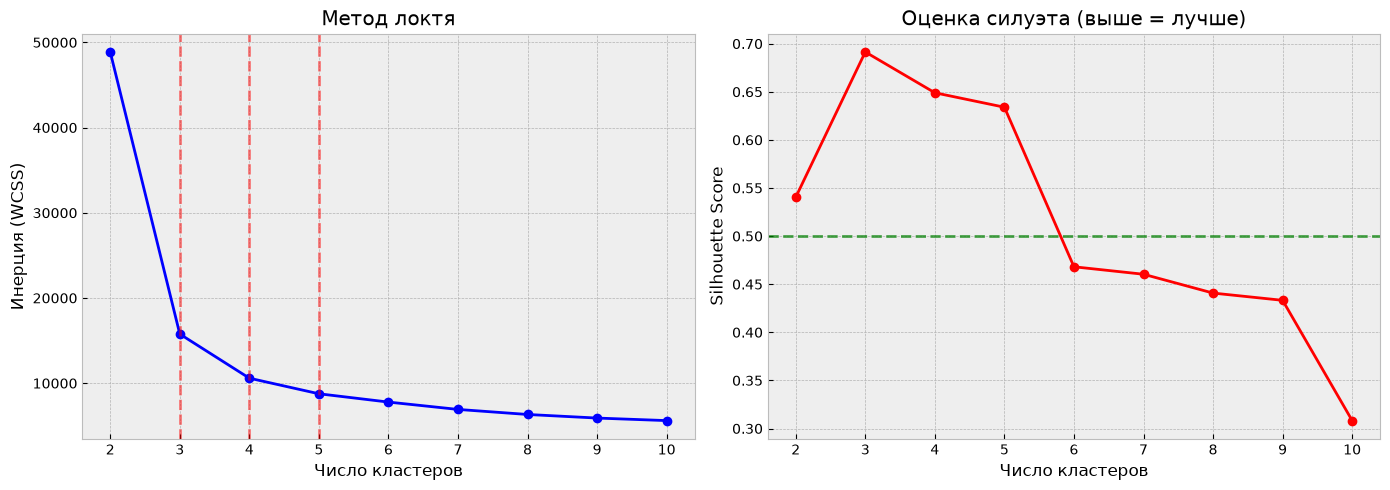

Оптимальное число кластеров по Silhouette: 3
Лучший Silhouette Score: 0.6914


In [40]:
# 2.1. Метод локтя (Inertia)
inertias = []
silhouette_scores = []
K_range = range(2, 11)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_cluster)
    inertias.append(kmeans.inertia_)
    silhouette_scores.append(silhouette_score(X_cluster, kmeans.labels_))

# 2.2. Визуализация
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# График инерции (локоть)
axes[0].plot(K_range, inertias, 'bo-')
axes[0].set_xlabel('Число кластеров')
axes[0].set_ylabel('Инерция (WCSS)')
axes[0].set_title('Метод локтя')
axes[0].grid(True)
# Добавляем вертикальные линии для наглядности
for k in [3, 4, 5]:
    axes[0].axvline(x=k, color='red', linestyle='--', alpha=0.5)

# График силуэта
axes[1].plot(K_range, silhouette_scores, 'ro-')
axes[1].set_xlabel('Число кластеров')
axes[1].set_ylabel('Silhouette Score')
axes[1].set_title('Оценка силуэта (выше = лучше)')
axes[1].grid(True)
axes[1].axhline(y=0.5, color='green', linestyle='--', alpha=0.7, label='Хороший порог')

plt.tight_layout()
# plt.savefig('clustering_elbow.png', dpi=300)
plt.show()

# 2.3. Вывод оптимального числа
optimal_k = K_range[np.argmax(silhouette_scores)]
print(f"Оптимальное число кластеров по Silhouette: {optimal_k}")
print(f"Лучший Silhouette Score: {max(silhouette_scores):.4f}")

In [41]:
k_optimal = 3
kmeans = KMeans(n_clusters=k_optimal, random_state=42, n_init=10)
cluster_labels = kmeans.fit_predict(X_cluster)

df_merged['cluster'] = np.nan
df_merged.loc[X_cluster.index, 'cluster'] = cluster_labels  

all_predictions = kmeans.cluster_centers_

print(f"\nЦентроиды кластеров:")
centroids_df = pd.DataFrame(
    all_predictions,
    columns=features_for_clustering
)
display(centroids_df)

cross_tab = pd.crosstab(
    df_merged.loc[X_cluster.index, 'тип_уноса'],
    df_merged.loc[X_cluster.index, 'cluster']
)

print("Сопряженность кластеров и ручной разметки:")
print(cross_tab)


Центроиды кластеров:


,lba10cq201,lba10cq201_mean_2h,lba10cq201_mean_6h,lba10cq204_std_6h,lba10cq202_std_6h,lba10cq201_std_2h,lba10cq201_std_6h,lba10cq201_mean_4h
0,9.097630,9.106988,9.096268,1.148949,0.061556,0.068062,0.091713,9.101374
1,8.909258,8.917379,8.916164,7.708624,0.279090,0.267214,0.333291,8.917807
2,6.420404,6.405124,6.418353,2.003871,0.448642,0.581451,0.696726,6.411359


Сопряженность кластеров и ручной разметки:
cluster                     0.0   1.0   2.0
тип_уноса                                  
Кислый унос (хлоридный)       8    31  2082
Натриевый унос (щелочной)   147  1328    16
Норма                      1855   228     8
Переходный режим             95   272   179


PCA — это метод сжатия информации (уменьшения размерности). Он берет данные с множеством признаков и находит новые оси, которые лучше всего описывают разброс данных. PC1 (Первая главная компонента) - это ось, которая "объясняет" максимальную долю изменчивости данных. PC2 (Вторая главная компонента) - Направление, перпендикулярное PC1, вдоль которого данные разбросаны вторыми по силе.

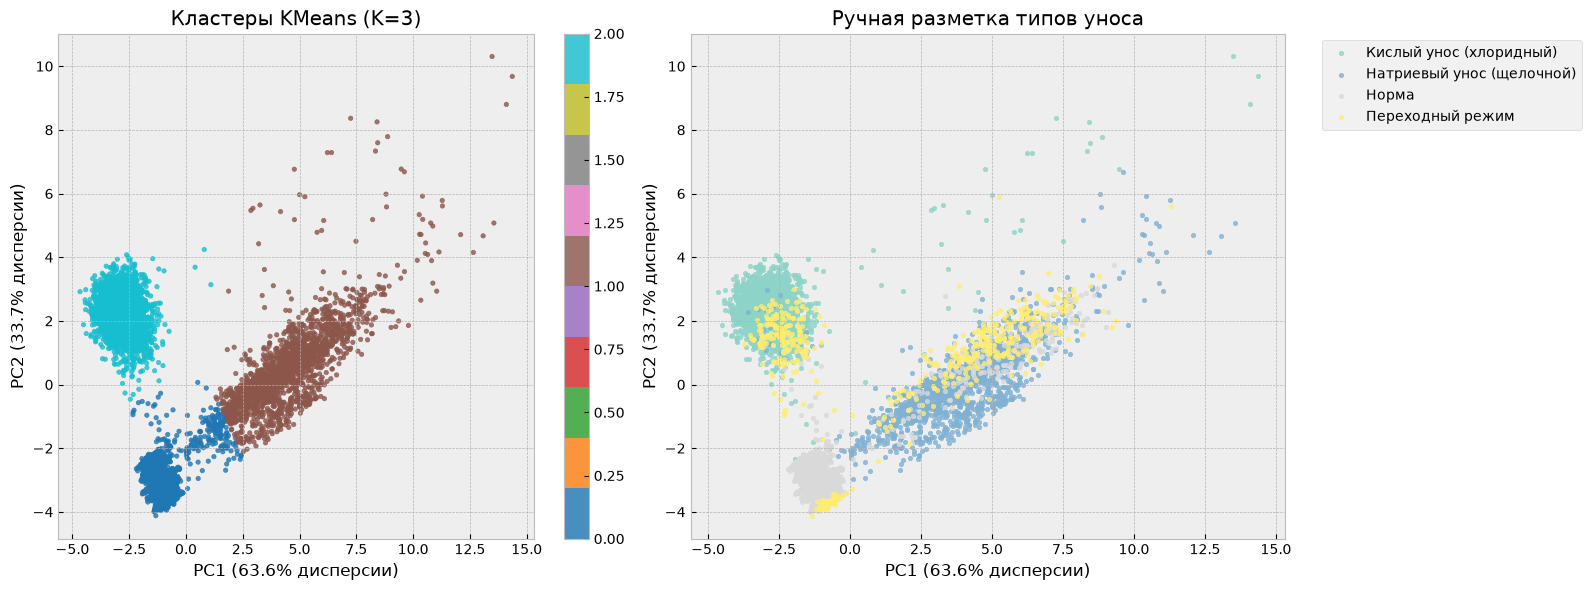

In [42]:
# 4.1. Уменьшаем размерность до 2D для визуализации используем метод главных компонентов
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_cluster)

# Создаем DataFrame для визуализации
viz_df = pd.DataFrame({
    'PC1': X_pca[:, 0],
    'PC2': X_pca[:, 1],
    'cluster': cluster_labels,
    'unos_type': df_merged.loc[X_cluster.index, 'тип_уноса']  # Ваша ручная разметка
})

# 4.2. Строим графики
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# График 1: Кластеры (KMeans)
scatter1 = axes[0].scatter(viz_df['PC1'], viz_df['PC2'], 
                           c=viz_df['cluster'], cmap='tab10', alpha=0.8, s=10)
axes[0].set_title(f'Кластеры KMeans (K={k_optimal})')
axes[0].set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.1%} дисперсии)')
axes[0].set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.1%} дисперсии)')
plt.colorbar(scatter1, ax=axes[0])

# График 2: Ручная разметка
unos_types_unique = viz_df['unos_type'].unique()
colors = plt.cm.Set3(np.linspace(0, 1, len(unos_types_unique)))
type_to_color = {t: colors[i] for i, t in enumerate(sorted(unos_types_unique))}

for unos_type in sorted(unos_types_unique):
    mask = viz_df['unos_type'] == unos_type
    axes[1].scatter(viz_df.loc[mask, 'PC1'], viz_df.loc[mask, 'PC2'], 
                    label=unos_type, color=type_to_color[unos_type], alpha=0.8, s=10)
axes[1].set_title('Ручная разметка типов уноса')
axes[1].set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.1%} дисперсии)')
axes[1].set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.1%} дисперсии)')
axes[1].legend(bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.savefig('clusters_vs_manual_labels.png', dpi=300)
plt.show()

In [43]:
df_13 = sub_datasets_dict['dataset_13']

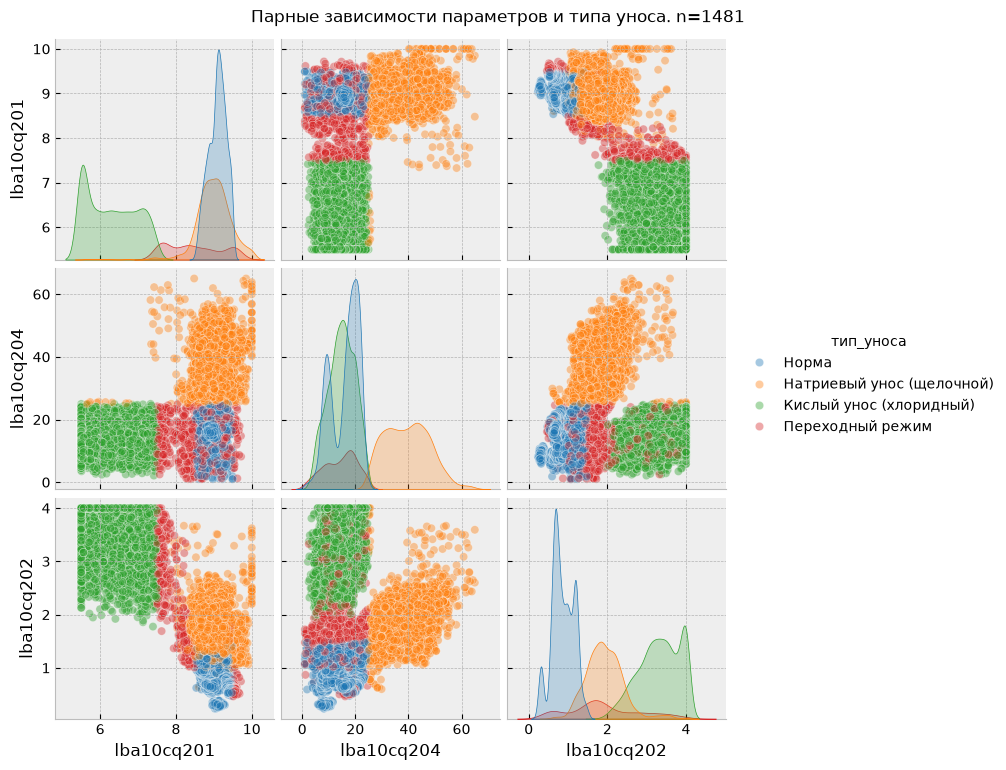

In [44]:
sns.pairplot(df_merged[['lba10cq201', 'lba10cq204', 'lba10cq202', 'тип_уноса']], 
             hue='тип_уноса', 
             palette='tab10',
             diag_kind='kde', 
             plot_kws={'alpha': 0.4})
plt.suptitle(f'Парные зависимости параметров и типа уноса. n={df_13.shape[0]}', y=1.02)
plt.show()

### <a id="s3_1"></a> 3.1 Вывод

"В ходе кластерного анализа данных установлено, что оптимальное число естественных кластеров по силуэту составляет 3 (Score =  0.6944). С помощью rule-based разметкой мы выделили 4 типа уносов, добавив переходный процесс. PCA-визуализация показала, что 63.6% дисперсии данных описывается первой главной компонентой, что говорит о корреляции параметров (pH и Na). В целом, кластеры  хорошо различимы и сгруппированы, за исключением нормального режима, смешивающегося с натриевым уносом. PCA-визуализаци rule-based разметки показывает, что "Переходный режим" не имеет четких границ и смешивается с другими группами. Необходимо специальное мнение эксперта - технолога относительно заданных правил разметки. График парных зависимостей так же показывает смешивание групп.

Предлагаю использовать данные с rule-based разметкой для обучения модели. 

## <a id="s4"></a> 4. Проверка корреляции и автокорреляции

Проверим есть ли автокорреляция между самыми большими датасетами. 

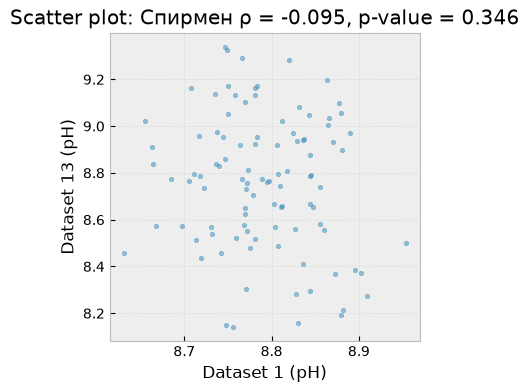

Корреляция Спирмена: -0.095
p-value: 0.346
Связь отсутствует


In [45]:
set1_ph = df_merged[df_merged['group_id']==1]['lba10cq201'].tail(100)
set13_ph = df_merged[df_merged['group_id']==13]['lba10cq201'].head(100)
corr_spearman, p_value = spearmanr(set1_ph, set13_ph)

plt.figure(figsize=(4, 4))
plt.scatter(set1_ph, set13_ph, alpha=0.5, s=10)
plt.xlabel('Dataset 1 (pH)')
plt.ylabel('Dataset 13 (pH)')
plt.title(f'Scatter plot: Спирмен ρ = {corr_spearman:.3f}, p-value = {p_value:.3f}')
plt.grid(True, alpha=0.3)
plt.show()
print(f"Корреляция Спирмена: {corr_spearman:.3f}")
print(f"p-value: {p_value:.3f}")

if abs(corr_spearman) < 0.2:
    print("Связь отсутствует")
elif abs(corr_spearman) < 0.5:
    print("Слабая связь")
else:
    print("Сильная связь (есть автокорреляция между сессиями)")

Преобразуем текстовую разметку наших классов, уберем лишние параметры. 

In [46]:
le = LabelEncoder()
df_merged['unos_type'] = le.fit_transform(df_merged['тип_уноса'])

In [47]:
mapping = dict(enumerate(le.classes_))
print(mapping)

{0: 'Кислый унос (хлоридный)', 1: 'Натриевый унос (щелочной)', 2: 'Норма', 3: 'Переходный режим'}


In [48]:
df_merged.columns

Index(['hal40cf001', 'lba10cq204', 'lba10cq202', 'lba10cq201', 'had10cl001',
       'hah90ct001', 'hha10cp001', 'had10cp001', 'lba10cf001', 'lba08cp001',
       'month', 'work', 'hour_sin', 'hour_cos', 'dow_sin', 'dow_cos', 'level',
       'ph', 'group_id', 'hours_from_start', 'lba10cq204_mean_2h',
       'lba10cq204_std_2h', 'lba10cq204_mean_4h', 'lba10cq204_std_4h',
       'lba10cq204_mean_6h', 'lba10cq204_std_6h', 'lba10cq204_delta_1',
       'lba10cq204_delta_2', 'lba10cq204_delta_3', 'lba10cq204__accel',
       'lba10cq202_mean_2h', 'lba10cq202_std_2h', 'lba10cq202_mean_4h',
       'lba10cq202_std_4h', 'lba10cq202_mean_6h', 'lba10cq202_std_6h',
       'lba10cq202_delta_1', 'lba10cq202_delta_2', 'lba10cq202_delta_3',
       'lba10cq202__accel', 'lba10cq201_mean_2h', 'lba10cq201_std_2h',
       'lba10cq201_mean_4h', 'lba10cq201_std_4h', 'lba10cq201_mean_6h',
       'lba10cq201_std_6h', 'lba10cq201_delta_1', 'lba10cq201_delta_2',
       'lba10cq201_delta_3', 'lba10cq201__accel', 'lba

Уберем из данных параметры, связанные с приборами измерения натрия и электропроводности. Посмотрим есть ли автокорреляция между параметрами.

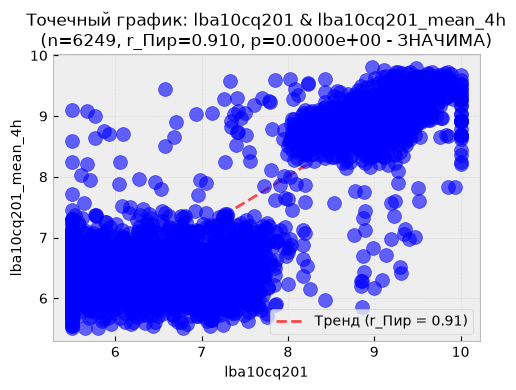

In [49]:
parametrs = ['lba10cq201', 'lba10cq201_mean_4h']
salt_removal(df_merged, parametrs,  method='pearson')

Согласно оценке корреляции по Пирсану есть сильная связь двух параметров, однако на графике видно, что точки сгруппированы в двух областях, дисперсия неравномерная, имеются выбросы и возможна нелинейная зависимость, т.к. точки не ложатся строго на прямую линию. Поэтому оценку автокорреляции будем делать по Спирману.

In [50]:
parameters = ['hal40cf001', 'lba10cq201', 'had10cl001',
       'hah90ct001', 'hha10cp001', 'had10cp001', 'lba10cf001', 'lba08cp001',
       'hour_sin', 'hour_cos', 'dow_sin', 'dow_cos', 
       'lba10cq201_mean_2h', 'lba10cq201_std_2h',
       'lba10cq201_mean_4h', 'lba10cq201_std_4h', 'lba10cq201_mean_6h',
       'lba10cq201_std_6h', 'lba10cq201_delta_1', 'lba10cq201_delta_2',
       'lba10cq201_delta_3', 'lba10cq201__accel']

In [51]:
corr_matrix = df_merged[parameters].corr(method='spearman')
corr_pairs = corr_matrix.where(
    np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
).stack().reset_index()

corr_pairs.columns = ['param1', 'param2', 'correlation']

# Фильтруем по модулю > 0.9
high_corr = corr_pairs[np.abs(corr_pairs['correlation']) > 0.9]

# Сортируем по убыванию абсолютной корреляции
high_corr = high_corr.reindex(
    high_corr['correlation'].abs().sort_values(ascending=False).index
)

print(high_corr)

                 param1              param2  correlation
204  lba10cq201_mean_4h  lba10cq201_mean_6h     0.982062
187  lba10cq201_mean_2h  lba10cq201_mean_4h     0.964345
189  lba10cq201_mean_2h  lba10cq201_mean_6h     0.950151
211   lba10cq201_std_4h   lba10cq201_std_6h     0.944010


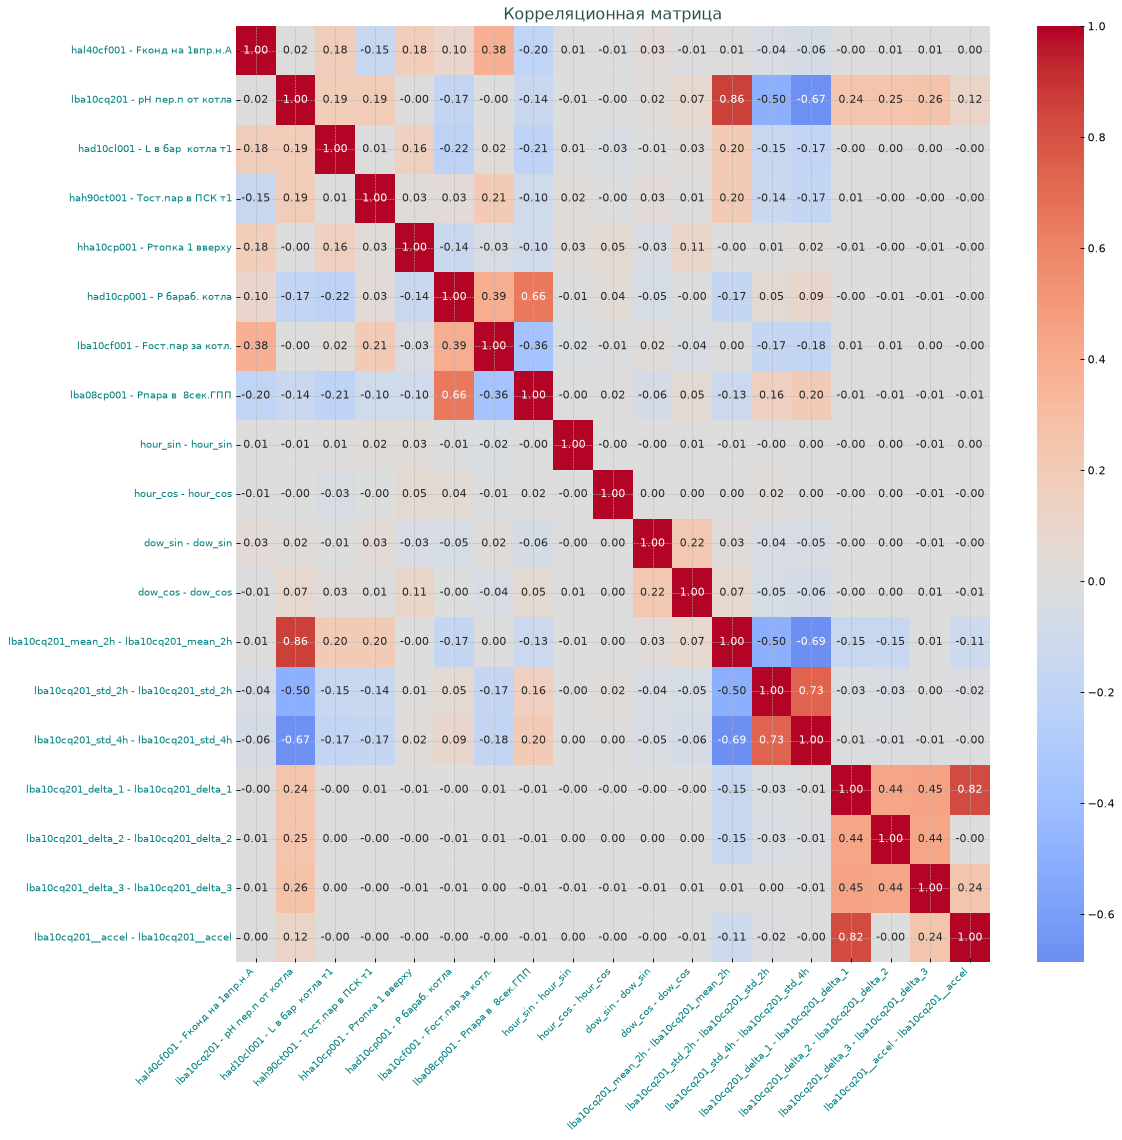

In [52]:
parameters = ['hal40cf001', 'lba10cq201', 'had10cl001',
       'hah90ct001', 'hha10cp001', 'had10cp001', 'lba10cf001', 'lba08cp001',
       'hour_sin', 'hour_cos', 'dow_sin', 'dow_cos', 
       'lba10cq201_mean_2h', 'lba10cq201_std_2h', 'lba10cq201_std_4h',
        'lba10cq201_delta_1', 'lba10cq201_delta_2', 'lba10cq201_delta_3', 'lba10cq201__accel']

modulekrug.plot_corr(df_merged, parameters, method='spearman', print_table=False)

Отберем нужные параметры и разобьем данные на две таблицы. Одну будем использовать для обучения, на другой протестируем модель.

In [53]:
parameters_for_model = ['hal40cf001', 'lba10cq201', 'had10cl001',
       'hah90ct001', 'hha10cp001', 'had10cp001', 'lba10cf001', 'lba08cp001',
       'hour_sin', 'hour_cos', 'dow_sin', 'dow_cos', 
       'lba10cq201_mean_2h', 'lba10cq201_std_2h',
       'lba10cq201_std_4h', 'lba10cq201_delta_1', 'lba10cq201_delta_2',
       'lba10cq201_delta_3', 'lba10cq201__accel', 
       'unos_type', 'group_id']
df_for_model = df_merged[parameters_for_model].copy()

In [54]:
df_train = df_for_model.query('group_id != 13')
df_test = df_for_model[df_for_model['group_id'] == 13]

In [55]:
df_train.to_csv('df_train.csv')
df_test.to_csv('df_test.csv')

### <a id="s4_1"></a> 4.1. Вывод

Для обучения моделий данные разделены на 2 выборки: обучающую и тестовую. В качестве финального теста возьмем dataset_13 (2017-09-01 - 2017-11-01), поскольку он обладает большой длительностью и содержит все четыре целевых класса (щелочной, кислый, переходный, норма). Это позволяет объективно оценить способность модели к различению всех типов уноса на репрезентативном, невидимом в обучении отрезке.

Все остальные сессии (1, 3, 5, 7, 9, 11, 15, 17) включены в обучение и валидацию. Хотя некоторые из них хронологически предшествуют dataset_13 (1, 3, 5, 7, 9, 11), а другие следуют за ним (15, 17), между сессиями имеются длительные разрывы (от нескольких дней до месяцев), в течение которых котёл останавливался или работал в иных режимах. Поэтому данные сессии не образуют непрерывного временного ряда с автокорреляцией — каждая сессия представляет собой отдельный "эпизод" работы оборудования. Порядок сессий во времени не несёт информативной закономерности для прогнозирования типа уноса в момент времени, а физические режимы работы котла циклически повторяются в разные периоды. Следовательно, использование более поздних сессий (15, 17) в обучении для предсказания более ранней (13) не является "подглядыванием" в будущее, так как между ними нет причинно-следственной временной связи, а модель обучается на разнообразных режимах, встречавшихся в разные календарные периоды. Такой подход максимизирует объём обучающих данных и увеличивает обобщающую способность модели. Для честной оценки гиперпараметров внутри обучения применяется групповая кросс-валидация (GroupKFold) с группировкой по отдельным сессиям, что гарантирует отсутствие перемешивания данных между разными эпизодами и предотвращает любую утечку информации.

## <a id="s5"></a> 5. Вывод

Мы наблюдаем ярко выраженную проблему с электропроводностью перегретого пара и pH (lba10cq202, lba10cq201). Во всех периодах высока доля критического уровня по этим праметрам. Это говорит о системной проблеме с солесодержанием в паре.

Коэффициент корреляции между pH пара и электропроводностью пара доходит до **r=-0,76** и  указывает на довольно сильную обратную связь. В нашем случае действует правило **«Много солей (высокая проводимость) → вода становится кислой (низкий pH)»** .

Стоит уделить особое внимание уровню pH, т.к. это напрямую влияет на **летучесть кремния**. Исследования показывают, что в кислой и нейтральной среде (pH < 9): кремниевая кислота существует преимущественно в недиссоциированной (молекулярной) форме (H₂SiO₃ или H₄SiO₄). Эта молекулярная форма гораздо более летуча и легко переходит в пар. Кремниевая кислота, переходя в пар, не влияет на pH, но при конденсации образует прочные, трудно смываемые силикатные отложения в трубах и на лопатках турбин. Эти отложения обладают низкой теплопроводностью, что может приводить к перегреву и разрушению труб. 

Na не может оказывать сильного влияния на pH, следовательно, есть другие соли, которые в обычных условиях нейтральны (например, хлорид натрия, хлорид кальция, сульфат магния). Но при нагреве до 300-500°C в паре происходит реакция обмена.
Самые опасные для котла соли — это хлориды магния (MgCl₂) и хлориды кальция (CaCl₂).

Вот как это работает на примере хлорида магния:

В обычной воде при 20°C: MgCl₂ просто плавает в виде ионов Mg²⁺ и Cl⁻. Среда нейтральная.

В перегретом паре при 300°C: MgCl₂ реагирует с водой (H₂O).

**Результат:**

- Магний соединяется с кислородом из воды → образуется нерастворимый оксид магния (MgO) — выпадает в накипь.**

- Хлор соединяется с водородом из воды → образуется СОЛЯНАЯ КИСЛОТА (HCl).**

#### Риск щелочной коррозии

В энергетике используют аммиачную (или аминовую) коррекцию pH. В питательную воду (которая идет в котел) добавляют аммиак (NH₃) или гидразин. Аммиак создает в воде щелочную среду (высокий pH). Это пассивирует металл (создает защитную пленку) и останавливает коррозию. Сами по себе молекулы аммиака почти не проводят ток. Они не диссоциируют на ионы так сильно, как соли. Высокие показатели pH говорят о том, что добавили больше, чем нужно амиака.  Но главный риск — это не сам аммиак, а щелочная коррозия металла котла, которая возникает при чрезмерном защелачивании котловой воды.

#### Натриевый унос (щелочной)

Это процесс, при котором в пар уносятся капельки котловой воды, обогащенные щелочами (в первую очередь NaOH).  Условия для этого складываются при сочетании двух факторов: 
- Высокий pH пара, который свидетельствует о том, что уносимые капли содержат не просто соли, а именно едкий натр (NaOH), делающий среду сильно щелочной.
- Высокая концентрация натрия (Na) в паре

#### Аварийный режим

Значение pH < 7.5 — это аварийный индикатор, который указывает на грубое нарушение водно-химического режима. Это состояние требует немедленного вмешательства, так как оно напрямую угрожает ресурсу и надежности котла.